# Optional clustering (issue #14)

Groups the 693 occupations in `ai_risk_v1.csv` by how the three indices rank them (Eloundou β with GPT-4 labels,
AIOE, Frey-Osborne), using k-means. Ranks, not raw scores, because the indices use different units.
Writes `data/processed/milestone_2/occupation_clusters.csv`.

In [10]:
import os
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/BTT Fall AI Studio (swytch 1b)'
except ImportError:
    BASE = os.path.dirname(os.getcwd())  # repo folder (this notebook is in notebooks/)

v1 = pd.read_csv(f'{BASE}/data/processed/milestone_1/v1/ai_risk_v1.csv', dtype={'soc': str})
RANKS = ['pct_eloundou_beta', 'pct_aioe', 'pct_frey_osborne']
X = v1[RANKS]

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## How many groups?
Silhouette measures how cleanly the groups separate (higher is better).

In [11]:
for k in range(2, 10):
    labels = KMeans(n_clusters=k, n_init=20, random_state=0).fit_predict(X)
    print(k, round(silhouette_score(X, labels), 3))

2 0.463
3 0.461
4 0.401
5 0.351
6 0.335
7 0.323
8 0.309
9 0.305


k = 2 and k = 3 score essentially the same (0.463 vs 0.461), so silhouette alone does not pick one. k = 3 is used
because it also pulls out the occupations that rank high on all three indices, the one place they agree; k = 2 merges
them into the other groups.

In [12]:
labels = KMeans(n_clusters=3, n_init=20, random_state=0).fit_predict(X)
v1['cluster'] = labels

# K-means numbers its groups arbitrarily, so renumber them 1-3 by their average Eloundou rank
order = v1.groupby('cluster')['pct_eloundou_beta'].mean().sort_values().index
v1['cluster'] = v1['cluster'].map({old: new for new, old in enumerate(order, start=1)})

v1.groupby('cluster').agg(
    occupations=('soc', 'size'),
    eloundou=('pct_eloundou_beta', 'mean'),
    aioe=('pct_aioe', 'mean'),
    frey_osborne=('pct_frey_osborne', 'mean'),
    job_zone=('onet_job_zone', 'mean'),
    median_wage=('bls_median_wage', 'median'),
).round(1)

,occupations,eloundou,aioe,frey_osborne,job_zone,median_wage
cluster,,,,,,
1,314,23.8,23.5,64.2,2.2,49015.0
2,271,68.6,71.7,21.4,3.9,79520.0
3,108,80.0,73.1,80.9,2.9,53090.0


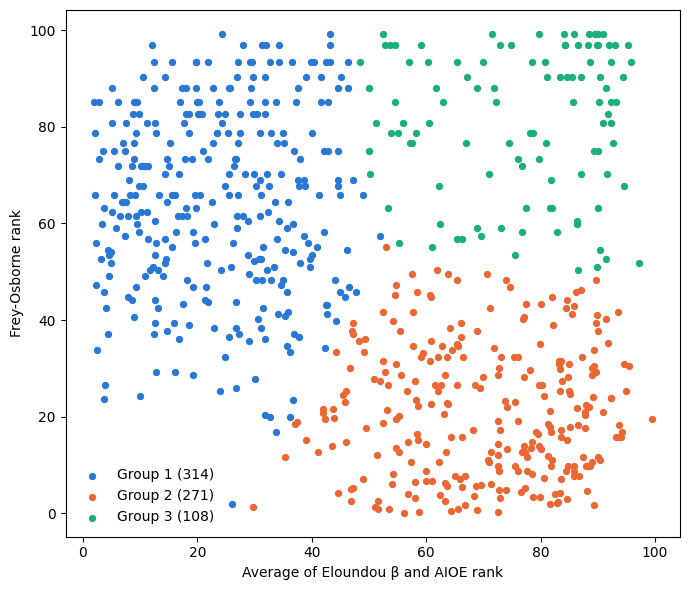

In [13]:
colors = {1: '#2a78d6', 2: '#eb6834', 3: '#1baf7a'}
newer_average = (v1['pct_eloundou_beta'] + v1['pct_aioe']) / 2

fig, ax = plt.subplots(figsize=(7, 6))
for number, group in v1.groupby('cluster'):
    ax.scatter(newer_average[group.index], group['pct_frey_osborne'], s=18, color=colors[number],
               label=f'Group {number} ({len(group)})')
ax.set_xlabel('Average of Eloundou β and AIOE rank')
ax.set_ylabel('Frey-Osborne rank')
ax.legend(frameon=False)
fig.tight_layout()
os.makedirs(f'{BASE}/notebooks/figures', exist_ok=True)
fig.savefig(f'{BASE}/notebooks/figures/clusters_scatter.png', dpi=130)
plt.show()

In [14]:
os.makedirs(f'{BASE}/data/processed/milestone_2', exist_ok=True)
v1[['soc', 'title', 'cluster'] + RANKS].to_csv(f'{BASE}/data/processed/milestone_2/occupation_clusters.csv', index=False)

## Result
Group 1 ranks low on the newer indices and high on Frey-Osborne (hands-on jobs, Job Zone ≈ 2.2). Group 2 is the
reverse (managers, professionals, Job Zone ≈ 3.9). Group 3 ranks high on all three (routine office and sales work).
Counts are unweighted; occupations missing from the merged table (e.g. postsecondary teachers) cannot appear.